# Faithfulness results (synthetic targets)

In [ ]:
from functools import reduce

import matplotlib.pyplot as plt

from mol_faith.notebooks.results_analysis.shared import (
    SYNTHETIC_RESULTS,
    SYNTHETIC_TARGET_COLORS,
    SYNTHETIC_TARGETS,
    aggregate_and_merge_normalized_fid,
    calculate_per_task_rank_panel,
    calculate_ranking_excluding_sign_effect,
    calculate_stats_by_method_target,
    combine_and_calculate_variance,
    compute_effect_sizes,
    compute_k_effect,
    count_positive_fid_negative_random,
    create_grouped_boxplot,
    create_grouped_violinplot,
    fit_fid_ols,
    kruskal_by,
    load_raw_data,
    load_raw_data_all_thres,
    perform_pca,
    plot_boxplot_grid_by_model,
    plot_k_effect_bars,
    plot_negative_deviations,
    plot_pca,
    plot_std_by_method_target,
    process_fidelity_df,
)


In [2]:
HUE_ORDER = ['Conjugated System', 'Benzene', 'Hbond Donor']
OUTPUT_DIR = SYNTHETIC_RESULTS / 'result_plots' / 'fid_general'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load data

In [3]:
raw_data = {label: load_raw_data(SYNTHETIC_RESULTS / folder, target_name)
            for label, (folder, target_name) in SYNTHETIC_TARGETS.items()}

benzene: 237,635 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.2]


conjugated_system: 240,471 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.2]


hbond_donor: 239,135 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.2]


## Random baseline (conjugated system)

In [4]:
conj_df = raw_data['Conjugated System']
conj_df[conj_df['explanation_method'] == 'random_explanation'].groupby('model').describe().T

model                         CNN          GAT          GCN          GIN  \
data_split_idx count  6900.000000  6900.000000  6900.000000  6900.000000   
               mean      2.000000     2.000000     2.000000     2.000000   
               std       1.414316     1.414316     1.414316     1.414316   
               min       0.000000     0.000000     0.000000     0.000000   
               25%       1.000000     1.000000     1.000000     1.000000   
               50%       2.000000     2.000000     2.000000     2.000000   
               75%       3.000000     3.000000     3.000000     3.000000   
               max       4.000000     4.000000     4.000000     4.000000   
target         count  6900.000000  6900.000000  6900.000000  6900.000000   
               mean      0.284230     0.284230     0.284230     0.284230   
               std       0.135795     0.135795     0.135795     0.135795   
               min       0.000000     0.000000     0.000000     0.000000   
               25%       0.187500     0.187500     0.187500     0.187500   
               50%       0.281250     0.281250     0.281250     0.281250   
               75%       0.375000     0.375000     0.375000     0.375000   
               max       1.000000     1.000000     1.000000     1.000000   
fid_plus       count  6900.000000  6900.000000  6900.000000  6900.000000   
               mean      0.004152     0.002322     0.001153     0.000775   
               std       0.012383     0.008409     0.008054     0.003872   
               min      -0.048767    -0.034314    -0.146457    -0.024456   
               25%      -0.002209    -0.001259    -0.001056    -0.000401   
               50%       0.003075     0.001001     0.000715     0.000125   
               75%       0.008986     0.004234     0.003478     0.001340   
               max       0.105893     0.136403     0.089929     0.086362   

model                 Transformer  
data_split_idx count  6900.000000  
               mean      2.000000  
               std       1.414316  
               min       0.000000  
               25%       1.000000  
               50%       2.000000  
               75%       3.000000  
               max       4.000000  
target         count  6900.000000  
               mean      0.284230  
               std       0.135795  
               min       0.000000  
               25%       0.187500  
               50%       0.281250  
               75%       0.375000  
               max       1.000000  
fid_plus       count  6900.000000  
               mean      0.004400  
               std       0.018804  
               min      -0.098599  
               25%      -0.004543  
               50%       0.002305  
               75%       0.010871  
               max       0.220785

## Normalize scores

In [5]:
target_data = {label: process_fidelity_df(df) for label, df in raw_data.items()}
data_by_target_name = {target_name: target_data[label] for label, (_, target_name) in SYNTHETIC_TARGETS.items()}

203,135 rows | {'faithful': 149075, 'unfaithful': 54060} | normalized_fid in [-1.000, 1.000]
205,971 rows | {'faithful': 154068, 'unfaithful': 51903} | normalized_fid in [-1.000, 1.000]


204,635 rows | {'faithful': 174450, 'unfaithful': 30185} | normalized_fid in [-1.000, 1.000]


## Kruskal-Wallis tests (model, method, target)

In [6]:
for group_cols in (['model', 'target'], ['explanation_method', 'target'], ['target']):
    display(kruskal_by(data_by_target_name, group_cols))

,test_name,H_statistic,p_value,n_groups,N,eta_squared,groups
0,Kruskal–Wallis (by model x target),12196.291554,0.0,15,613741,0.01985,"[CNN_benzene, CNN_conjugated_system, CNN_hbond..."


,test_name,H_statistic,p_value,n_groups,N,eta_squared,groups
0,Kruskal–Wallis (by explanation_method x target),75152.668868,0.0,24,613741,0.122417,"[gnn_explainer_benzene, gnn_explainer_conjugat..."


,test_name,H_statistic,p_value,n_groups,N,eta_squared,groups
0,Kruskal–Wallis (by target),6125.640348,0.0,3,613741,0.009978,"[benzene, conjugated_system, hbond_donor]"


## PCA

PCA on ['fid_normalized_median_benzene', 'fid_normalized_median_conjugated_system', 'fid_normalized_median_hbond_donor'], explained variance ratio [0.88726589 0.06003569]


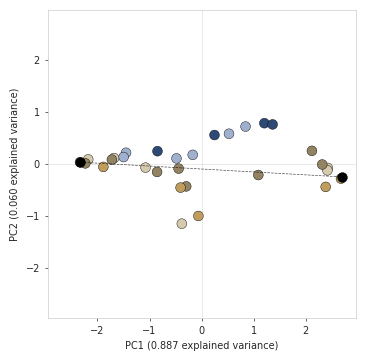

In [7]:
pca_df, pca, _, loadings, fid_columns = perform_pca(aggregate_and_merge_normalized_fid(data_by_target_name))
plot_pca(pca_df, pca, loadings, fid_columns, figsize=(7.2, 4), point_size=50, labelsize=7, tick_label_size=7,
         save_path=OUTPUT_DIR / 'pca_plot_loadings.svg');

## Boxplots

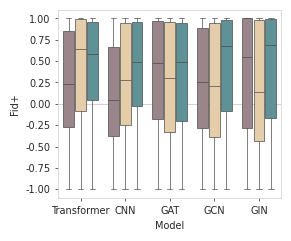

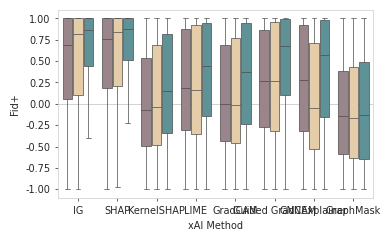

In [8]:
model_fig = create_grouped_boxplot(target_data, 'normalized_fid', 'model', figsize=(3, 2.5),
                                   target_colors=SYNTHETIC_TARGET_COLORS, hue_order=HUE_ORDER, tick_rotation=0,
                                   output_dir=OUTPUT_DIR)
create_grouped_boxplot(target_data, 'normalized_fid', 'explanation_method', figsize=(4, 2.5),
                       target_colors=SYNTHETIC_TARGET_COLORS, hue_order=HUE_ORDER, tick_rotation=0,
                       output_dir=OUTPUT_DIR, reference_fig=model_fig, enable_reference_yticks=True);

## Violin plots

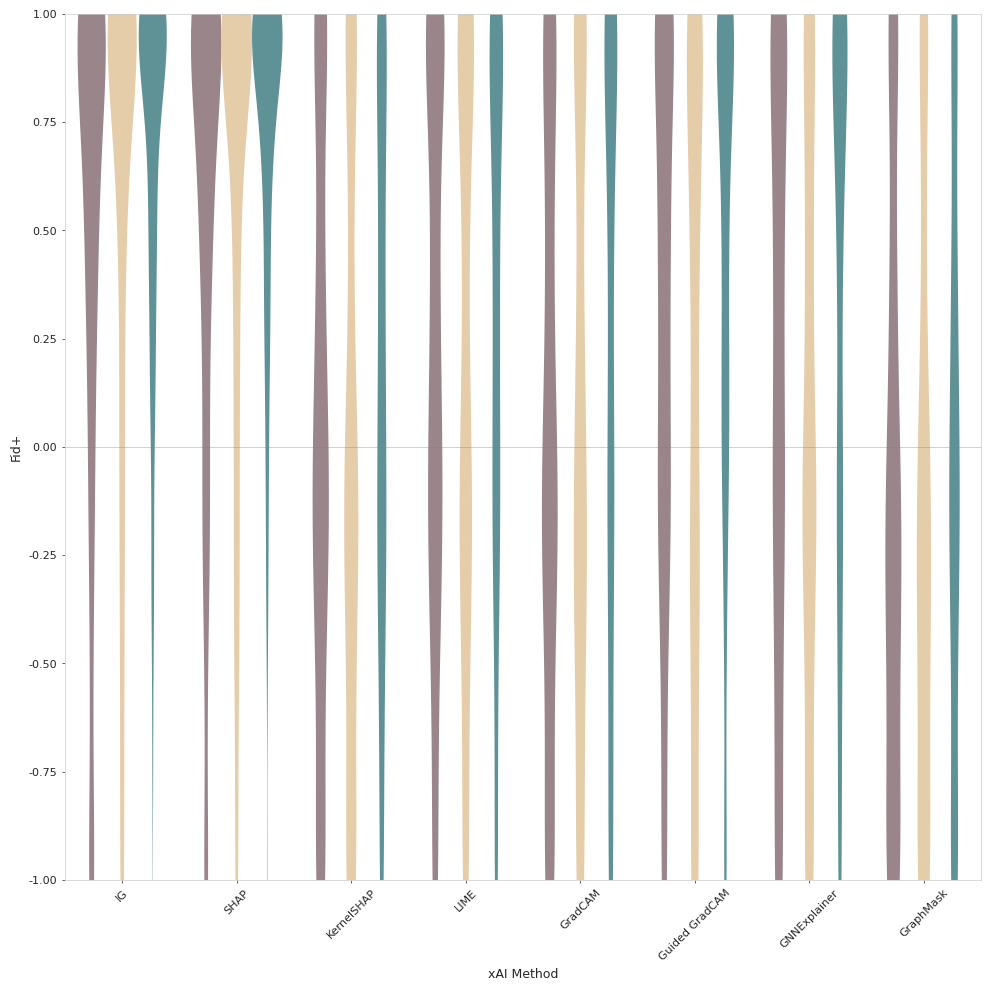

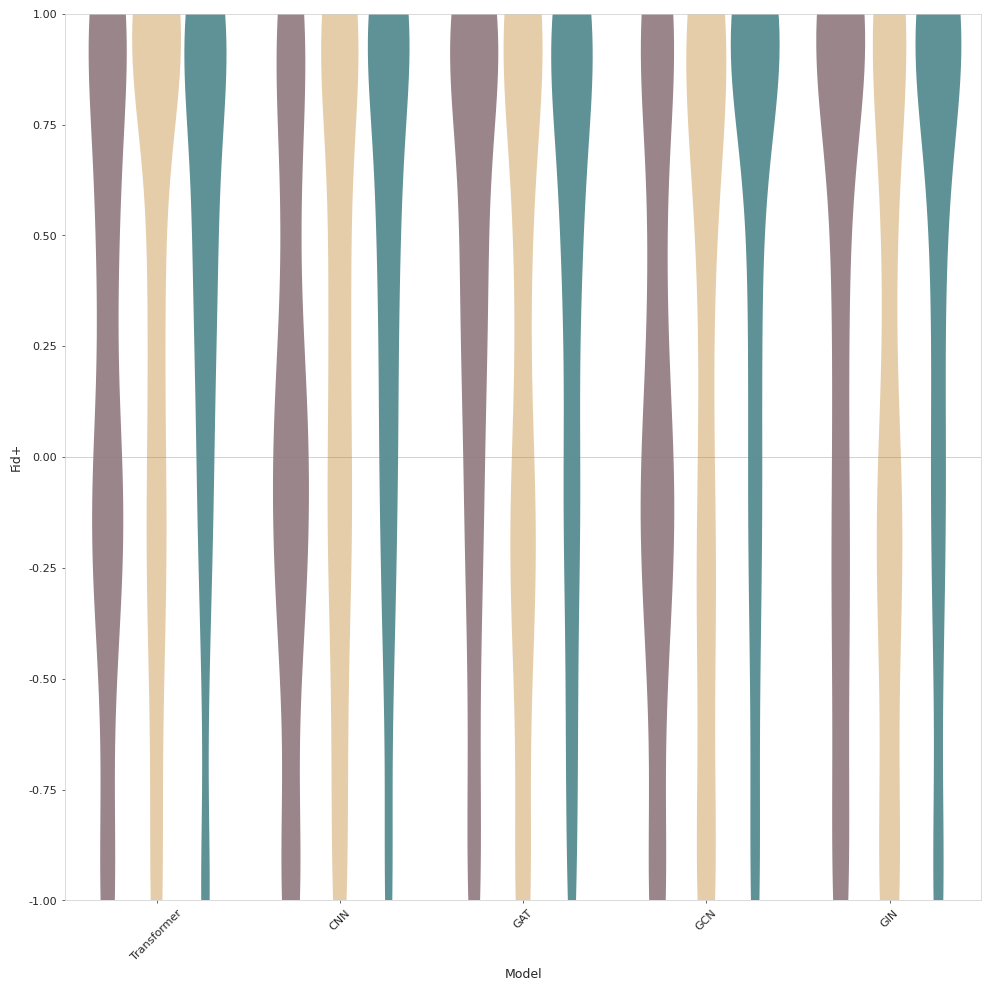

In [9]:
for group_col in ('explanation_method', 'model'):
    create_grouped_violinplot(target_data, 'normalized_fid', group_col, figsize=(10, 10),
                              target_colors=SYNTHETIC_TARGET_COLORS, hue_order=HUE_ORDER)

## Sign normalization effect

In [10]:
for by in ({}, {'by_model': True}, {'by_model': True, 'by_method': True}):
    display(count_positive_fid_negative_random(target_data, **by))

,dataset,n_cases,n_total,pct_cases
0,Benzene,60742,203135,29.90
1,Conjugated System,61433,205971,29.83
2,Hbond Donor,55364,204635,27.06


,dataset,model,n_cases,n_total,pct_cases
0,Benzene,CNN,11215,38758,28.94
1,Benzene,GAT,11389,41400,27.51
2,Benzene,GCN,16191,53977,30.00
3,Benzene,GIN,13801,41400,33.34
4,Benzene,Transformer,8146,27600,29.51
5,Conjugated System,CNN,11021,41176,26.77
6,Conjugated System,GAT,12354,41400,29.84
7,Conjugated System,GCN,15380,54395,28.27
8,Conjugated System,GIN,14459,41400,34.93
9,Conjugated System,Transformer,8219,27600,29.78


,dataset,model,explanation_method,n_cases,n_total,pct_cases
0,Benzene,CNN,GradCAM,1827,6900,26.48
1,Benzene,CNN,Guided GradCAM,1311,4258,30.79
2,Benzene,CNN,IG,2136,6900,30.96
3,Benzene,CNN,KernelSHAP,1822,6900,26.41
4,Benzene,CNN,LIME,1894,6900,27.45
...,...,...,...,...,...,...
85,Hbond Donor,GIN,SHAP,2292,6900,33.22
86,Hbond Donor,Transformer,IG,1727,6900,25.03
87,Hbond Donor,Transformer,KernelSHAP,1674,6900,24.26
88,Hbond Donor,Transformer,LIME,1712,6900,24.81


In [11]:
for group_col in ('model', 'explanation_method'):
    display(calculate_ranking_excluding_sign_effect(target_data, group_col=group_col))

Excluded 177,539 of 613,741 rows (28.93%) with the sign effect (fid_plus and fid_plus_random have opposite signs).


,data,rank,model,n,mean,median,std
0,excluding sign effect,1,Transformer,59560,0.261,0.296,0.518
1,excluding sign effect,2,GAT,89324,0.194,0.216,0.556
2,excluding sign effect,3,GCN,115788,0.182,0.188,0.560
3,excluding sign effect,4,GIN,83682,0.183,0.166,0.594
4,excluding sign effect,5,CNN,87848,0.133,0.117,0.497
5,all data,1,Transformer,82800,0.333,0.479,0.642
6,all data,2,GIN,124199,0.274,0.477,0.715
7,all data,3,GAT,124200,0.280,0.436,0.672
8,all data,4,GCN,161244,0.259,0.388,0.681
9,all data,5,CNN,121298,0.234,0.282,0.643


Excluded 177,539 of 613,741 rows (28.93%) with the sign effect (fid_plus and fid_plus_random have opposite signs).


,data,rank,explanation_method,n,mean,median,std
0,excluding sign effect,1,SHAP,70658,0.471,0.630,0.491
1,excluding sign effect,2,IG,70965,0.427,0.577,0.508
2,excluding sign effect,3,Guided GradCAM,24315,0.194,0.221,0.526
3,excluding sign effect,4,LIME,74751,0.135,0.100,0.531
4,excluding sign effect,5,GNNExplainer,44129,0.114,0.074,0.549
5,excluding sign effect,6,GradCAM,29970,0.063,-0.003,0.526
6,excluding sign effect,7,KernelSHAP,76188,0.011,-0.046,0.507
7,excluding sign effect,8,GraphMask,45226,-0.114,-0.147,0.482
8,all data,1,SHAP,103500,0.576,0.832,0.549
9,all data,2,IG,103500,0.535,0.797,0.575


### Per-task rank panel

In [12]:
for group_col in ('model', 'explanation_method'):
    display(calculate_per_task_rank_panel(target_data, group_col=group_col))

task        Benzene           Conjugated System           Hbond Donor  \
data            all excluding               all excluding         all   
model                                                                   
CNN               3         3                 5         5           5   
GAT               2         2                 2         1           4   
GCN               4         4                 3         3           2   
GIN               5         5                 1         2           1   
Transformer       1         1                 4         4           3   

task                   
data        excluding  
model                  
CNN                 5  
GAT                 4  
GCN                 1  
GIN                 3  
Transformer         2

task               Benzene           Conjugated System           Hbond Donor  \
data                   all excluding               all excluding         all   
explanation_method                                                             
GNNExplainer             7         7                 3         4           4   
GradCAM                  5         5                 6         6           6   
GraphMask                8         8                 8         8           8   
Guided GradCAM           3         3                 4         3           3   
IG                       2         2                 2         2           2   
KernelSHAP               6         6                 7         7           7   
LIME                     4         4                 5         5           5   
SHAP                     1         1                 1         1           1   

task                          
data               excluding  
explanation_method            
GNNExplainer               4  
GradCAM                    6  
GraphMask                  8  
Guided GradCAM             3  
IG                         2  
KernelSHAP                 7  
LIME                       5  
SHAP                       1

## xAI methods per model

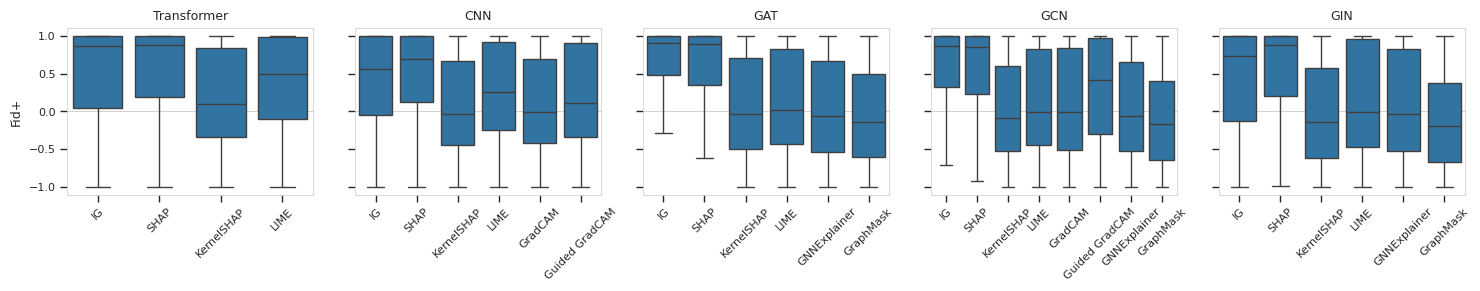

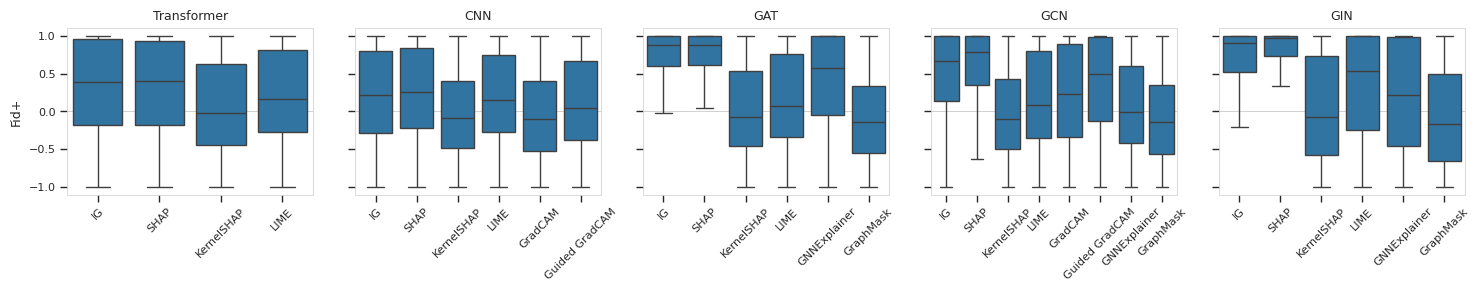

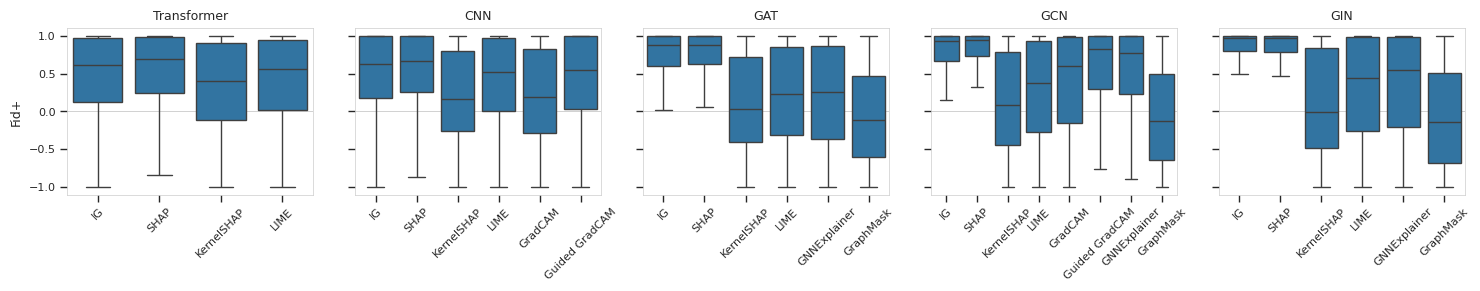

In [13]:
for label, (folder, _) in SYNTHETIC_TARGETS.items():
    plot_boxplot_grid_by_model(target_data[label], output_dir=SYNTHETIC_RESULTS / folder / 'result_plots')
    plt.show()

## Summary table

In [14]:
variance_df = combine_and_calculate_variance(target_data)
variance_df.to_latex(
    OUTPUT_DIR / 'supplementary_fid_variance_table.tex',
    index=False,
    float_format='%.3f',
    column_format='lllrllll',
    caption=(
        'Summary of normalized F-Fid$^+$ statistics across all model--method--target '
        'combinations. The table reports mean, median, standard deviation, and variance '
        'of normalized F-Fid$^+$ values across molecules for each configuration. '
        'High standard deviation values indicate large input-dependent variation '
        'in faithfulness scores within the same model and explanation method.'
    ),
    label='tab:supp_fid_variation',
    escape=False,
)
print(f"Median std: {variance_df['std'].median()}")
variance_df

Median std: 0.651


,model,explanation_method,target,n,mean,median,std,var
68,GIN,IG,Hbond Donor,6900,0.796,0.967,0.382,0.146
76,GIN,SHAP,Conjugated System,6900,0.758,0.965,0.438,0.192
77,GIN,SHAP,Hbond Donor,6900,0.803,0.965,0.363,0.132
59,GCN,SHAP,Hbond Donor,6900,0.775,0.939,0.377,0.142
50,GCN,IG,Hbond Donor,6900,0.738,0.929,0.410,0.168
...,...,...,...,...,...,...,...,...
22,GAT,GraphMask,Conjugated System,6900,-0.091,-0.143,0.627,0.393
65,GIN,GraphMask,Hbond Donor,6900,-0.086,-0.145,0.687,0.473
64,GIN,GraphMask,Conjugated System,6900,-0.082,-0.165,0.690,0.477
42,GCN,GraphMask,Benzene,6900,-0.101,-0.172,0.665,0.443


## Standard deviation

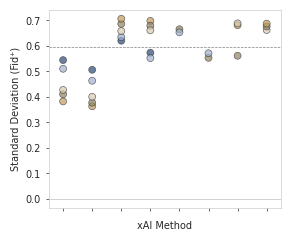

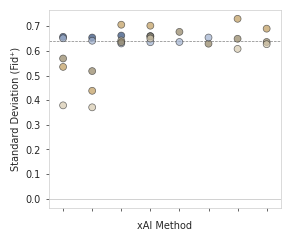

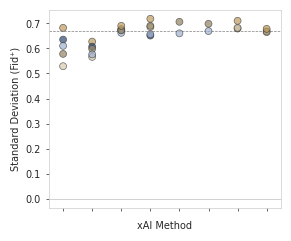

In [15]:
plot_std_by_method_target(variance_df);

In [16]:
calculate_stats_by_method_target(target_data, group_cols=['explanation_method'])

,explanation_method,n,median,std,var
0,GNNExplainer,62099,0.256877,0.689718,0.475711
1,GradCAM,41400,0.111168,0.678668,0.460590
2,GraphMask,62100,-0.147141,0.666088,0.443673
3,Guided GradCAM,34142,0.427245,0.649373,0.421685
4,IG,103500,0.796982,0.574624,0.330193
5,KernelSHAP,103500,-0.015151,0.670311,0.449316
6,LIME,103500,0.268715,0.668050,0.446291
7,SHAP,103500,0.831934,0.548799,0.301180


## Fid+ correlation between targets (shared molecules)

In [17]:
keys = ['model', 'smiles', 'explanation_method']
medians = [df.groupby(keys, as_index=False)['normalized_fid'].median()
           .rename(columns={'normalized_fid': f'normalized_fid_{label}'})
           for label, df in target_data.items()]
common_df = reduce(lambda a, b: a.merge(b, on=keys), medians)
common_df[[f'normalized_fid_{label}' for label in target_data]].corr(method='spearman')

,normalized_fid_Benzene,normalized_fid_Conjugated System,normalized_fid_Hbond Donor
normalized_fid_Benzene,1.000000,0.118933,0.143065
normalized_fid_Conjugated System,0.118933,1.000000,0.155517
normalized_fid_Hbond Donor,0.143065,0.155517,1.000000


## OLS analysis

`normalized_fid ~ model * explanation_method + target_name` with SEs clustered by molecule. The first entry of each order is the baseline (GIN / GCN, IG, hbond donor).

In [18]:
OLS_SPECS = {
    'supplementary_fid_effect_size_table': {
        'model_order': ['GIN', 'GAT', 'GCN', 'Transformer', 'CNN'],
        'method_order': ['integrated_gradients', 'shap_sampling', 'lime', 'kernel_shap'],
        'target_order': ['hbond_donor', 'conjugated_system', 'benzene'],
    },
    'supplementary_fid_effect_size_table_graph': {
        'model_order': ['GIN', 'GCN', 'GAT'],
        'method_order': ['integrated_gradients', 'shap_sampling', 'lime', 'kernel_shap', 'gnn_explainer', 'graph_mask'],
        'target_order': ['hbond_donor', 'benzene', 'conjugated_system'],
    },
    'supplementary_fid_effect_size_table_conv': {
        'model_order': ['GCN', 'CNN'],
        'method_order': ['integrated_gradients', 'shap_sampling', 'lime', 'kernel_shap', 'grad_cam', 'guided_grad_cam'],
        'target_order': ['hbond_donor', 'benzene', 'conjugated_system'],
    },
}
ols_models = {}
for name, spec in OLS_SPECS.items():
    ols_models[name] = fit_fid_ols(target_data, **spec)
    display(ols_models[name].summary())
    effect_sizes = compute_effect_sizes(ols_models[name])
    effect_sizes.to_latex(OUTPUT_DIR / f'{name}.tex', float_format='%.4f')
    display(effect_sizes)

414,000 samples


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         normalized_fid   R-squared:                       0.142
Model:                            OLS   Adj. R-squared:                  0.141
Method:                 Least Squares   F-statistic:                     3193.
Date:                Fri, 09 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:45:38   Log-Likelihood:            -3.8038e+05
No. Observations:              414000   AIC:                         7.608e+05
Df Residuals:                  413978   BIC:                         7.610e+05
Df Model:                          21                                         
Covariance Type:              cluster                                         
============================================================================================================================
                                                               coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------------
Intercept                                                    0.7129      0.005    154.204      0.000       0.704       0.722
model[T.GAT]                                                 0.0718      0.005     14.987      0.000       0.062       0.081
model[T.GCN]                                                -0.0216      0.005     -4.356      0.000      -0.031      -0.012
model[T.Transformer]                                        -0.2011      0.006    -34.202      0.000      -0.213      -0.190
model[T.CNN]                                                -0.2558      0.006    -43.715      0.000      -0.267      -0.244
explanation_method[T.shap_sampling]                          0.0825      0.004     22.849      0.000       0.075       0.090
explanation_method[T.lime]                                  -0.3886      0.005    -73.610      0.000      -0.399      -0.378
explanation_method[T.kernel_shap]                           -0.6019      0.006   -107.145      0.000      -0.613      -0.591
target_name[T.conjugated_system]                            -0.1574      0.004    -38.035      0.000      -0.166      -0.149
target_name[T.benzene]                                      -0.1334      0.004    -29.733      0.000      -0.142      -0.125
model[T.GAT]:explanation_method[T.shap_sampling]            -0.0885      0.005    -19.549      0.000      -0.097      -0.080
model[T.GCN]:explanation_method[T.shap_sampling]            -0.0442      0.005     -9.129      0.000      -0.054      -0.035
model[T.Transformer]:explanation_method[T.shap_sampling]    -0.0477      0.005     -9.993      0.000      -0.057      -0.038
model[T.CNN]:explanation_method[T.shap_sampling]            -0.0260      0.005     -4.997      0.000      -0.036      -0.016
model[T.GAT]:explanation_method[T.lime]                     -0.1610      0.007    -23.521      0.000      -0.174      -0.148
model[T.GCN]:explanation_method[T.lime]                     -0.0510      0.007     -7.293      0.000      -0.065      -0.037
model[T.Transformer]:explanation_method[T.lime]              0.2832      0.007     43.509      0.000       0.270       0.296
model[T.CNN]:explanation_method[T.lime]                      0.2947      0.007     42.964      0.000       0.281       0.308
model[T.GAT]:explanation_method[T.kernel_shap]              -0.0387      0.007     -5.452      0.000      -0.053      -0.025
model[T.GCN]:explanation_method[T.kernel_shap]               0.0262      0.007      3.625      0.000       0.012       0.040
model[T.Transformer]:explanation_method[T.kernel_shap]       0.3432      0.007     47.577      0.000       0.329       0.357
model[T.CNN]:explanation_method[T.kernel_shap]               0.3024      0.007     

,sum_sq,df,F,PR(>F),eta_sq,eta_sq_partial
model,605.357408,4.0,411.477910,0.0,0.001855,0.003960
explanation_method,16144.397801,3.0,14631.715580,0.0,0.049477,0.095867
target_name,596.024721,2.0,810.268457,0.0,0.001827,0.003899
model:explanation_method,4439.458483,12.0,1005.873595,0.0,0.013605,0.028331
Residual,152258.871632,413978.0,NaN,NaN,0.466618,0.500000


372,599 samples


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         normalized_fid   R-squared:                       0.183
Model:                            OLS   Adj. R-squared:                  0.183
Method:                 Least Squares   F-statistic:                     4131.
Date:                Fri, 09 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:45:38   Log-Likelihood:            -3.5294e+05
No. Observations:              372599   AIC:                         7.059e+05
Df Residuals:                  372579   BIC:                         7.061e+05
Df Model:                          19                                         
Covariance Type:              cluster                                         
====================================================================================================================
                                                       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------
Intercept                                            0.6995      0.005    146.211      0.000       0.690       0.709
model[T.GCN]                                        -0.0216      0.005     -4.356      0.000      -0.031      -0.012
model[T.GAT]                                         0.0718      0.005     14.987      0.000       0.062       0.081
explanation_method[T.shap_sampling]                  0.0825      0.004     22.848      0.000       0.075       0.090
explanation_method[T.lime]                          -0.3886      0.005    -73.610      0.000      -0.399      -0.378
explanation_method[T.kernel_shap]                   -0.6019      0.006   -107.145      0.000      -0.613      -0.591
explanation_method[T.gnn_explainer]                 -0.4344      0.005    -83.972      0.000      -0.445      -0.424
explanation_method[T.graph_mask]                    -0.7095      0.006   -125.451      0.000      -0.721      -0.698
target_name[T.benzene]                              -0.1656      0.005    -33.226      0.000      -0.175      -0.156
target_name[T.conjugated_system]                    -0.0851      0.005    -18.125      0.000      -0.094      -0.076
model[T.GCN]:explanation_method[T.shap_sampling]    -0.0442      0.005     -9.129      0.000      -0.054      -0.035
model[T.GAT]:explanation_method[T.shap_sampling]    -0.0885      0.005    -19.549      0.000      -0.097      -0.080
model[T.GCN]:explanation_method[T.lime]             -0.0510      0.007     -7.293      0.000      -0.065      -0.037
model[T.GAT]:explanation_method[T.lime]             -0.1610      0.007    -23.521      0.000      -0.174      -0.148
model[T.GCN]:explanation_method[T.kernel_shap]       0.0262      0.007      3.625      0.000       0.012       0.040
model[T.GAT]:explanation_method[T.kernel_shap]      -0.0387      0.007     -5.452      0.000      -0.053      -0.025
model[T.GCN]:explanation_method[T.gnn_explainer]     0.0403      0.007      5.962      0.000       0.027       0.054
model[T.GAT]:explanation_method[T.gnn_explainer]    -0.0569      0.007     -8.173      0.000      -0.071      -0.043
model[T.GCN]:explanation_method[T.graph_mask]        0.0318      0.007      4.384      0.000       0.018       0.046
model[T.GAT]:explanation_method[T.graph_mask]       -0.0493      0.007     -6.865      0.000      -0.063      -0.035
==============================================================================
Omnibus:                    18463.061   Durbin-Watson:                   1.969
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            12961.409
Skew:                          -0.350   Prob(JB):                         0.00
Kurtosis:                       2.414   Cond. No.                         27

,sum_sq,df,F,PR(>F),eta_sq,eta_sq_partial
model,76.812544,2.0,98.650969,3.434703e-43,0.000241,0.000529
explanation_method,27113.773475,5.0,13928.974930,0.000000e+00,0.085235,0.157488
target_name,430.628598,2.0,553.059771,1.335805e-229,0.001354,0.002960
model:explanation_method,384.153917,10.0,98.674393,1.109756e-196,0.001208,0.002641
Residual,145050.481581,372579.0,NaN,NaN,0.455981,0.500000


241,142 samples


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         normalized_fid   R-squared:                       0.111
Model:                            OLS   Adj. R-squared:                  0.111
Method:                 Least Squares   F-statistic:                     2672.
Date:                Fri, 09 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:45:39   Log-Likelihood:            -2.2658e+05
No. Observations:              241142   AIC:                         4.532e+05
Df Residuals:                  241128   BIC:                         4.533e+05
Df Model:                          13                                         
Covariance Type:              cluster                                         
======================================================================================================================
                                                         coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------
Intercept                                              0.7306      0.005    156.326      0.000       0.721       0.740
model[T.CNN]                                          -0.2342      0.006    -42.315      0.000      -0.245      -0.223
explanation_method[T.shap_sampling]                    0.0383      0.003     11.318      0.000       0.032       0.045
explanation_method[T.lime]                            -0.4395      0.005    -89.352      0.000      -0.449      -0.430
explanation_method[T.kernel_shap]                     -0.5756      0.005   -112.197      0.000      -0.586      -0.566
explanation_method[T.grad_cam]                        -0.3880      0.005    -75.304      0.000      -0.398      -0.378
explanation_method[T.guided_grad_cam]                 -0.2092      0.005    -39.501      0.000      -0.220      -0.199
target_name[T.benzene]                                -0.1750      0.006    -31.627      0.000      -0.186      -0.164
target_name[T.conjugated_system]                      -0.2336      0.005    -43.315      0.000      -0.244      -0.223
model[T.CNN]:explanation_method[T.shap_sampling]       0.0183      0.005      3.634      0.000       0.008       0.028
model[T.CNN]:explanation_method[T.lime]                0.3456      0.007     53.101      0.000       0.333       0.358
model[T.CNN]:explanation_method[T.kernel_shap]         0.2761      0.007     39.213      0.000       0.262       0.290
model[T.CNN]:explanation_method[T.grad_cam]            0.0935      0.007     13.215      0.000       0.080       0.107
model[T.CNN]:explanation_method[T.guided_grad_cam]     0.0745      0.007     10.771      0.000       0.061       0.088
==============================================================================
Omnibus:                    18157.653   Durbin-Watson:                   1.987
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            12128.812
Skew:                          -0.434   Prob(JB):                         0.00
Kurtosis:                       2.327   Cond. No.                         19.0
==============================================================================

Notes:
[1] Standard Errors are robust to cluster correlation (cluster)
"""

,sum_sq,df,F,PR(>F),eta_sq,eta_sq_partial
model,265.298837,1.0,691.885009,6.117582e-148,0.001349,0.002861
explanation_method,9155.240373,5.0,4775.274275,0.000000e+00,0.046569,0.090098
target_name,780.291932,2.0,1017.479563,0.000000e+00,0.003969,0.008369
model:explanation_method,1478.160137,5.0,770.992327,0.000000e+00,0.007519,0.015736
Residual,92458.974014,241128.0,NaN,NaN,0.470297,0.500000


In [19]:
compute_effect_sizes(ols_models['supplementary_fid_effect_size_table'], typ=3)

,sum_sq,df,F,PR(>F),eta_sq,eta_sq_partial
Intercept,8745.756102,1.0,23778.914035,0.0,0.026736,0.054320
model,1719.349835,4.0,1168.688889,0.0,0.005256,0.011166
explanation_method,7094.135980,3.0,6429.436466,0.0,0.021687,0.044518
target_name,596.024721,2.0,810.268457,0.0,0.001822,0.003899
model:explanation_method,4439.458483,12.0,1005.873595,0.0,0.013572,0.028331
Residual,152258.871632,413978.0,NaN,NaN,0.465463,0.500000


In [20]:
for name in ('supplementary_fid_effect_size_table_graph', 'supplementary_fid_effect_size_table_conv'):
    print(ols_models[name].summary().as_latex())

\begin{center}
\begin{tabular}{lclc}
\toprule
\textbf{Dep. Variable:}                                     & normalized\_fid  & \textbf{  R-squared:         } &      0.183   \\
\textbf{Model:}                                             &       OLS        & \textbf{  Adj. R-squared:    } &      0.183   \\
\textbf{Method:}                                            &  Least Squares   & \textbf{  F-statistic:       } &      4131.   \\
\textbf{Date:}                                              & Fri, 09 Oct 2026 & \textbf{  Prob (F-statistic):} &      0.00    \\
\textbf{Time:}                                              &     12:45:39     & \textbf{  Log-Likelihood:    } & -3.5294e+05  \\
\textbf{No. Observations:}                                  &      372599      & \textbf{  AIC:               } &  7.059e+05   \\
\textbf{Df Residuals:}                                      &      372579      & \textbf{  BIC:               } &  7.061e+05   \\
\textbf{Df Model:}                          

## Parameter k analysis

In [21]:
k_effects = {
    label: compute_k_effect(process_fidelity_df(load_raw_data_all_thres(SYNTHETIC_RESULTS / folder, target_name)))
    for label, (folder, target_name) in SYNTHETIC_TARGETS.items()
}

benzene: 2,138,715 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]


1,828,215 rows | {'faithful': 1317742, 'unfaithful': 510473} | normalized_fid in [-1.000, 1.000]


conjugated_system: 2,164,239 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]


1,853,739 rows | {'faithful': 1343374, 'unfaithful': 510365} | normalized_fid in [-1.000, 1.000]


hbond_donor: 2,152,215 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]


1,841,715 rows | {'faithful': 1553249, 'unfaithful': 288466} | normalized_fid in [-1.000, 1.000]


### Benzene

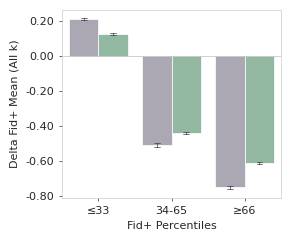

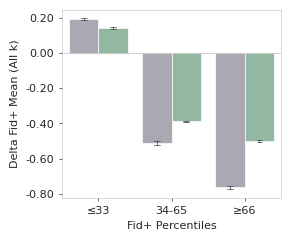

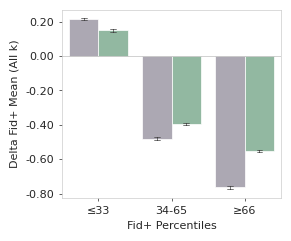

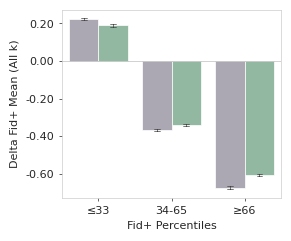

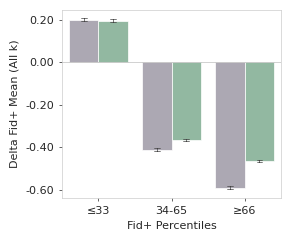

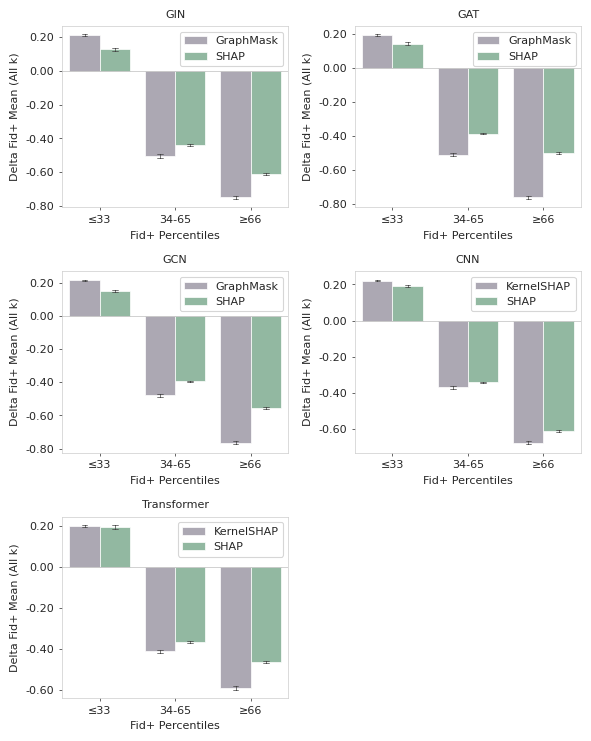

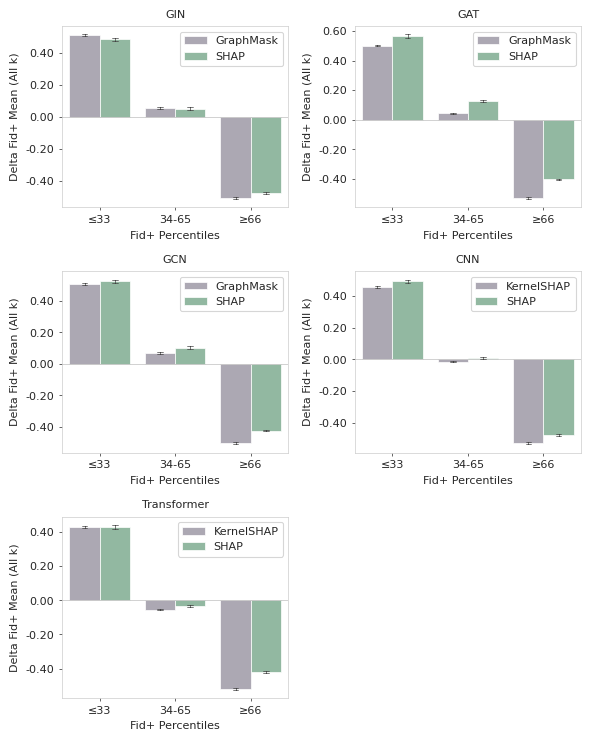

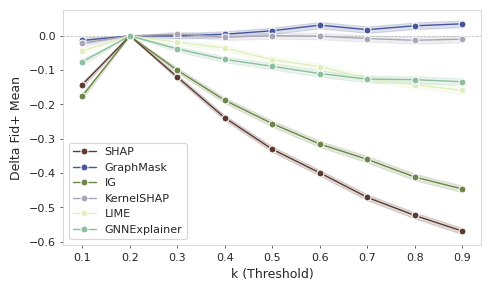

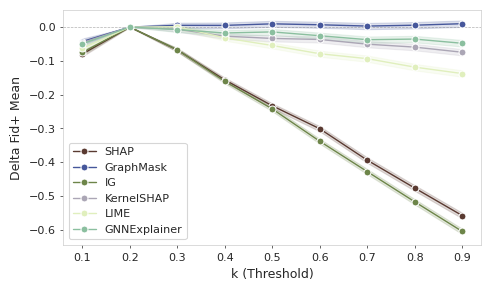

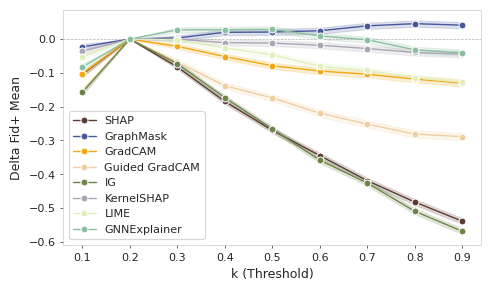

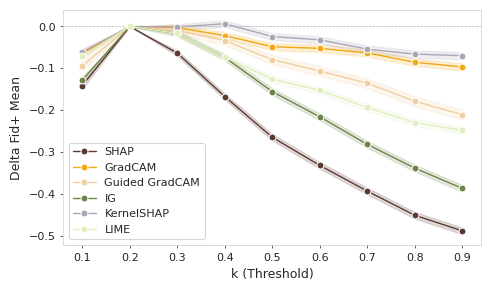

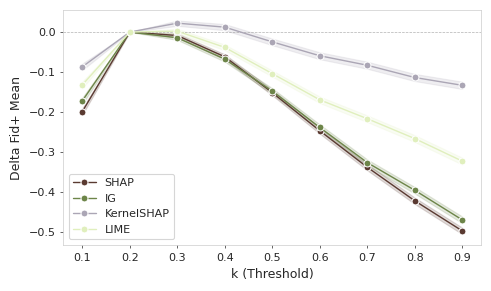

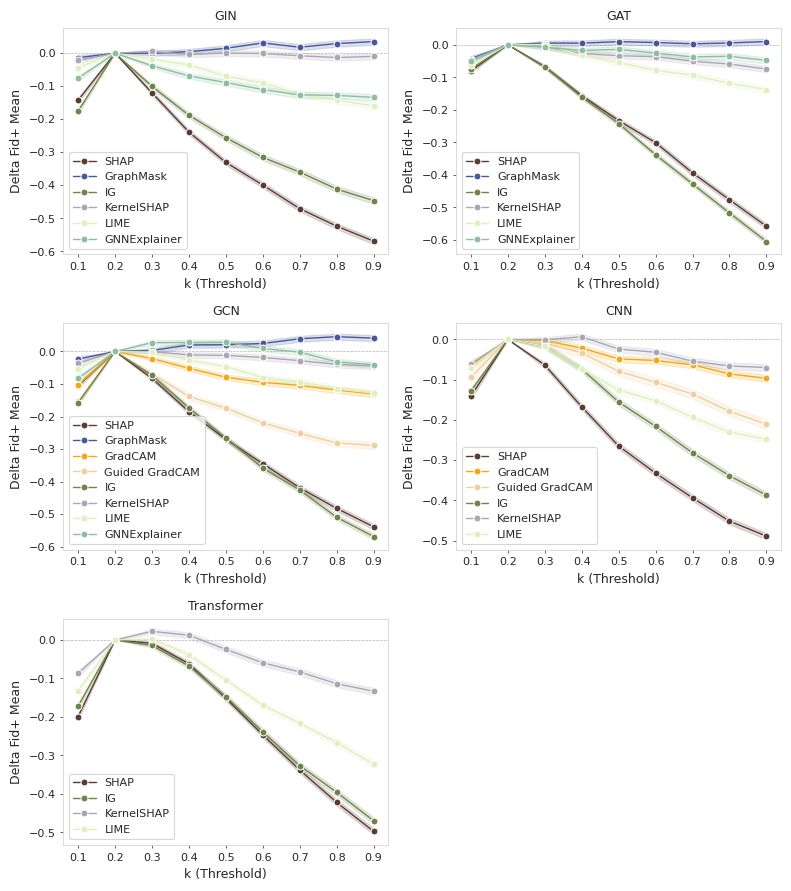

In [22]:
k_effect_df = k_effects['Benzene']
output_dir = SYNTHETIC_RESULTS / 'benzene_target' / 'result_plots'
plot_k_effect_bars(k_effect_df, output_dir)
plot_negative_deviations(k_effect_df, output_dir)

In [23]:
gin_df = k_effect_df[k_effect_df['model'] == 'GIN']
delta_cols = [f'delta_{k / 10:.1f}' for k in range(3, 10)]
gin_df[delta_cols].mean(axis=1).groupby(gin_df['explanation_method'], sort=False).mean().rename('mean delta (GIN)')

explanation_method
gnn_explainer          -0.099101
graph_mask              0.018907
integrated_gradients   -0.296828
kernel_shap            -0.004214
lime                   -0.091370
shap_sampling          -0.378965
Name: mean delta (GIN), dtype: float64

### Conjugated System

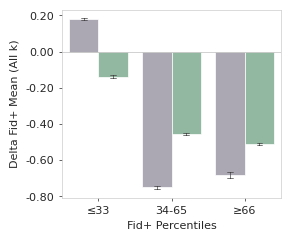

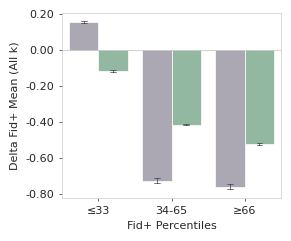

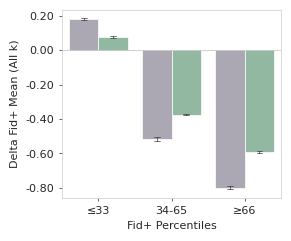

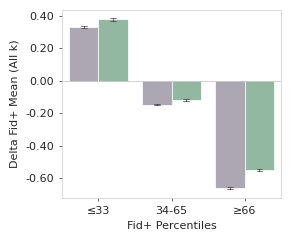

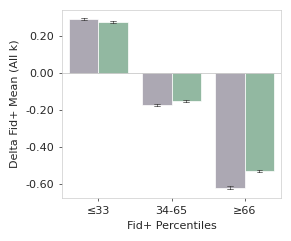

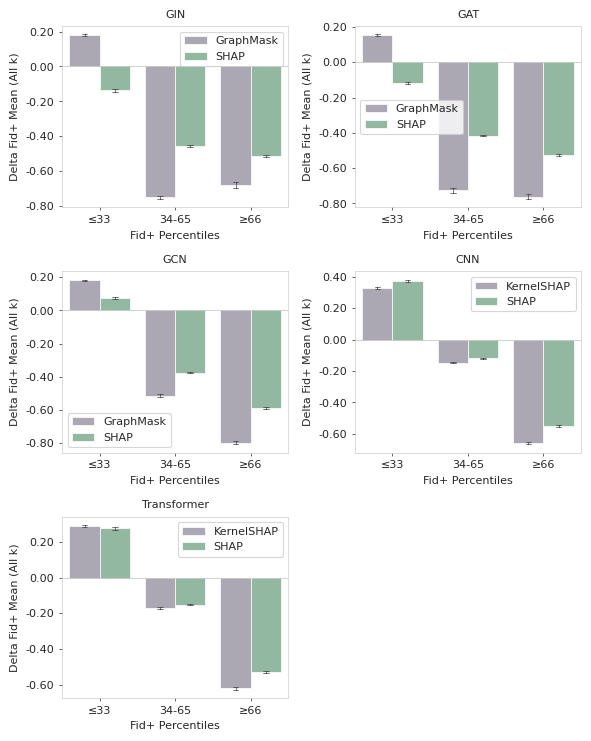

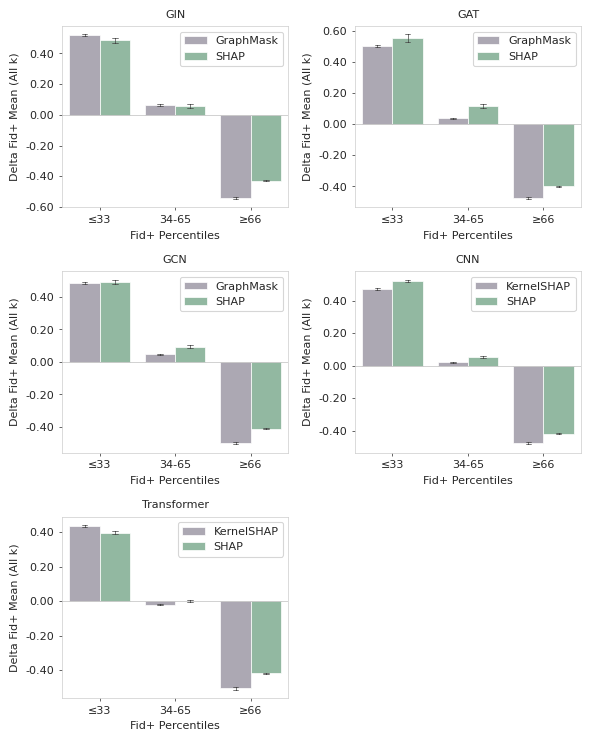

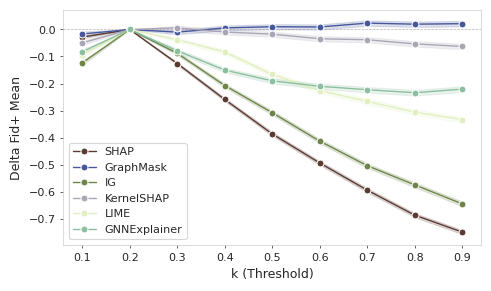

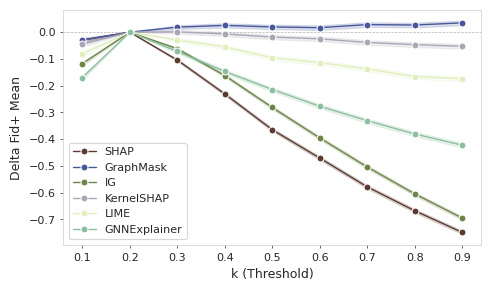

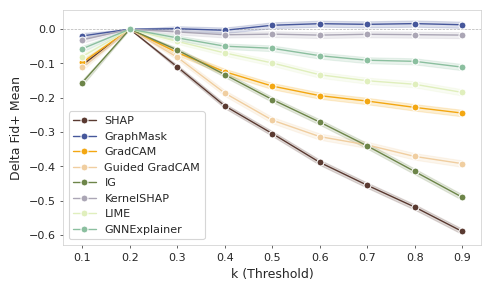

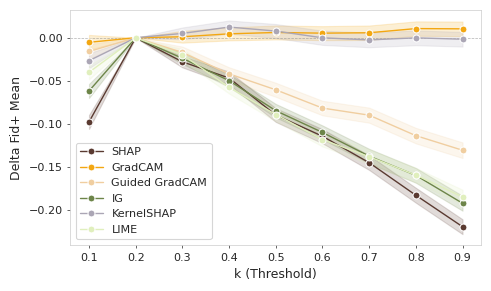

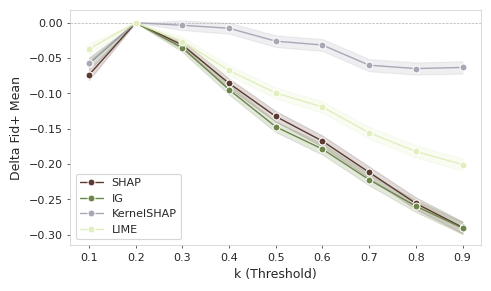

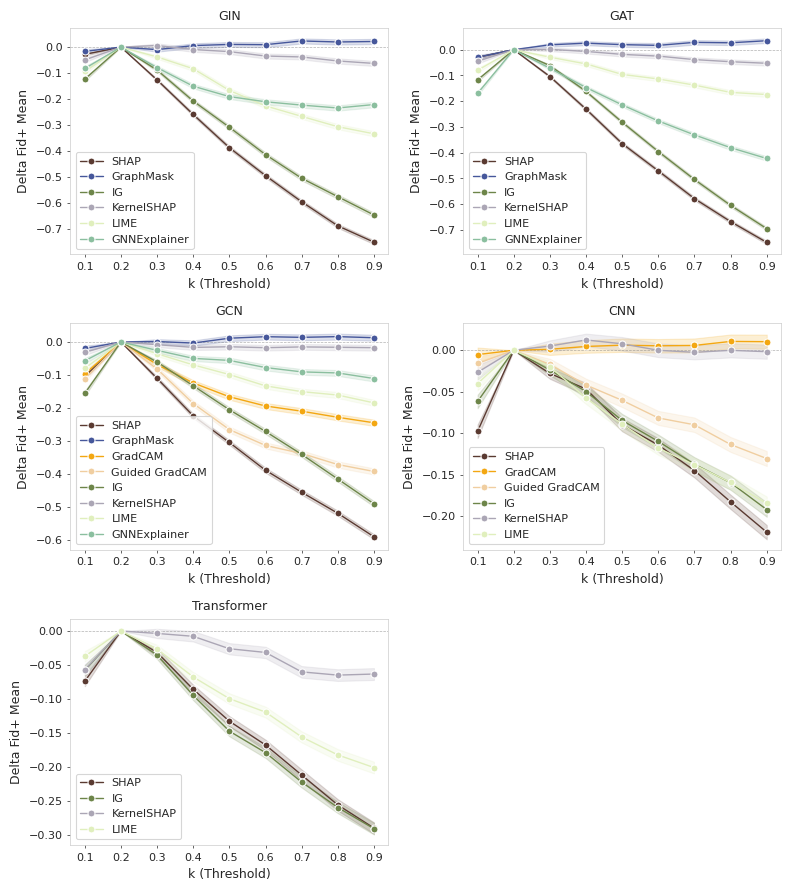

In [24]:
k_effect_df = k_effects['Conjugated System']
output_dir = SYNTHETIC_RESULTS / 'conjugated_system_target' / 'result_plots'
plot_k_effect_bars(k_effect_df, output_dir)
plot_negative_deviations(k_effect_df, output_dir)

In [25]:
gin_df = k_effect_df[k_effect_df['model'] == 'GIN']
delta_cols = [f'delta_{k / 10:.1f}' for k in range(3, 10)]
gin_df[delta_cols].mean(axis=1).groupby(gin_df['explanation_method'], sort=False).mean().rename('mean delta (GIN)')

explanation_method
gnn_explainer          -0.186860
graph_mask              0.011464
integrated_gradients   -0.391812
kernel_shap            -0.029865
lime                   -0.202798
shap_sampling          -0.471246
Name: mean delta (GIN), dtype: float64

### Hbond Donor

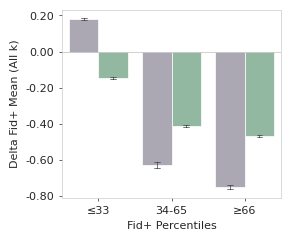

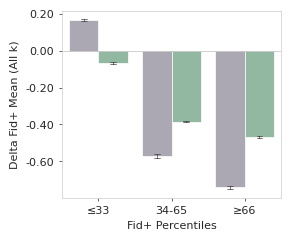

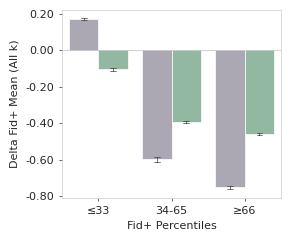

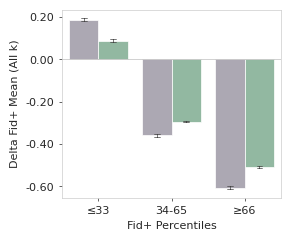

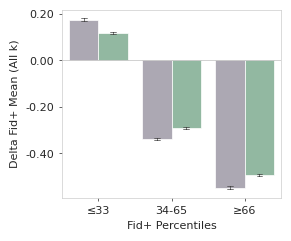

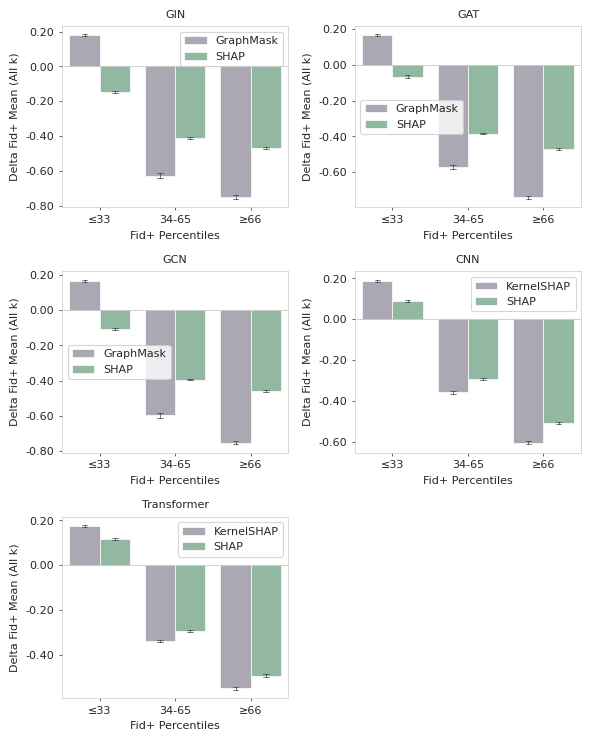

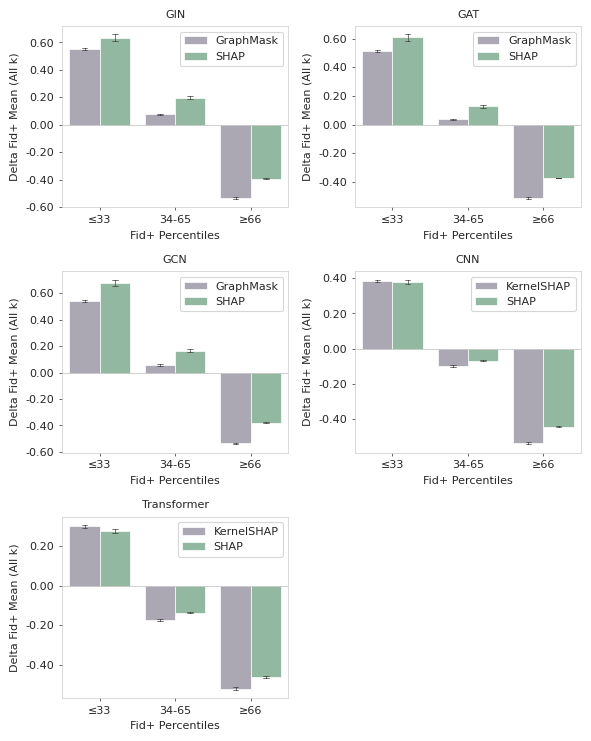

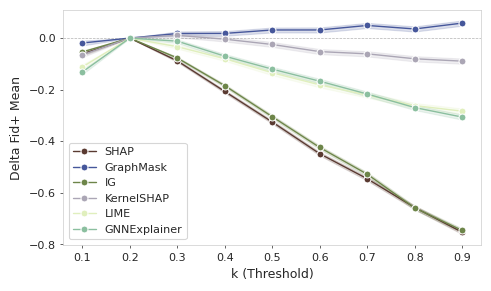

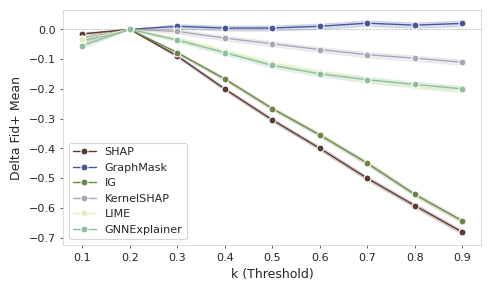

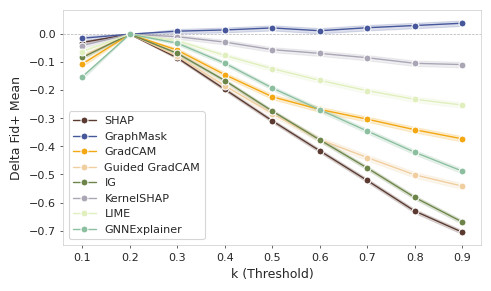

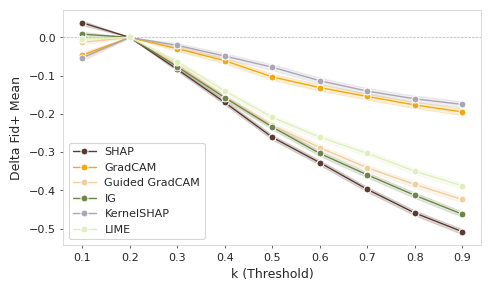

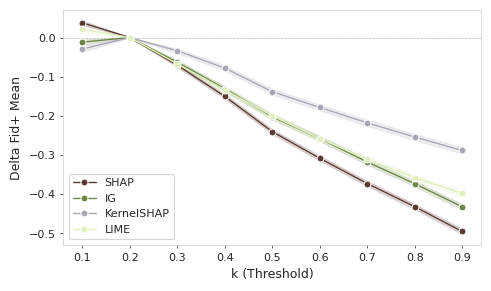

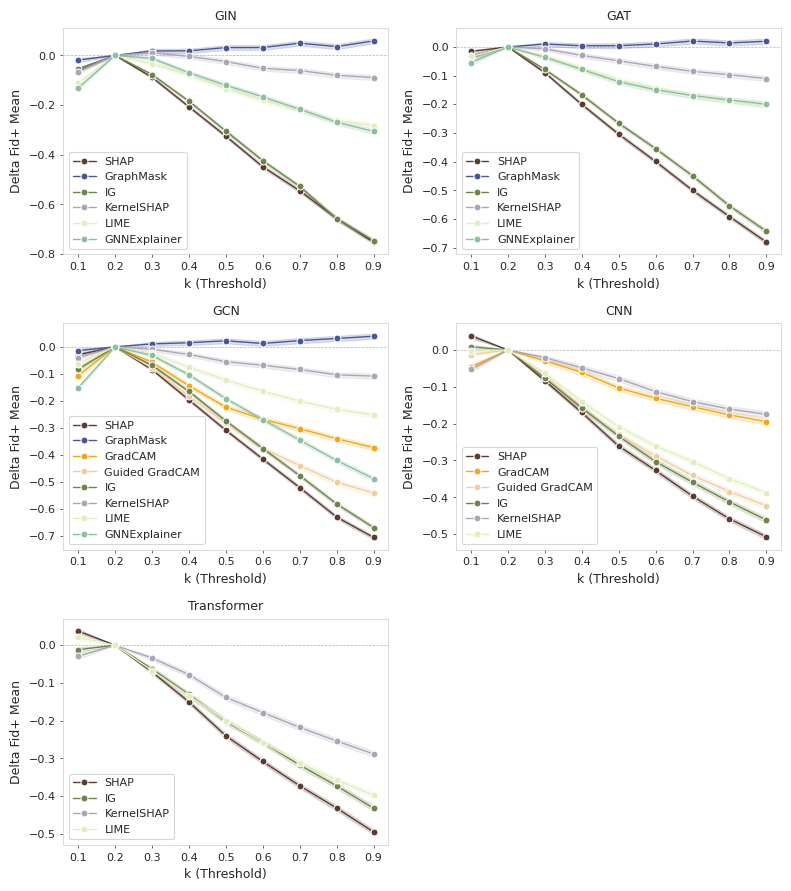

In [26]:
k_effect_df = k_effects['Hbond Donor']
output_dir = SYNTHETIC_RESULTS / 'hbond_donor' / 'result_plots'
plot_k_effect_bars(k_effect_df, output_dir)
plot_negative_deviations(k_effect_df, output_dir)

In [27]:
gin_df = k_effect_df[k_effect_df['model'] == 'GIN']
delta_cols = [f'delta_{k / 10:.1f}' for k in range(3, 10)]
gin_df[delta_cols].mean(axis=1).groupby(gin_df['explanation_method'], sort=False).mean().rename('mean delta (GIN)')

explanation_method
gnn_explainer          -0.166124
graph_mask              0.034405
integrated_gradients   -0.417586
kernel_shap            -0.043127
lime                   -0.170834
shap_sampling          -0.432160
Name: mean delta (GIN), dtype: float64